In [1]:
print(1+1)

2


In [2]:
import numpy as np
import pandas as pd

In [3]:
df = pd.read_csv('churn_data.csv')

### Removing Nulls and Outliers

In [4]:
bin = [18, 30, 40, 50, 60, 70, 80]
df['Age_Group'] = pd.cut(df['Age'], bins=bin)
df['Age_Group'].value_counts()

Age_Group
(18, 30]    20894
(30, 40]    17814
(40, 50]    17528
(60, 70]    17517
(50, 60]    17407
(70, 80]     7155
Name: count, dtype: int64

In [5]:
bin2 = [0, 5, 10, 15, 20, 25]
df['Premium_Hike_Trend_Group'] = pd.cut(df['Premium_Hike_Trend_%'], bins=bin2)
df['Premium_Hike_Trend_Group'].value_counts()

Premium_Hike_Trend_Group
(5, 10]     20156
(0, 5]      20072
(15, 20]    19969
(10, 15]    19863
(20, 25]    19721
Name: count, dtype: int64

In [6]:
df = df.drop(columns=['Age', 'Premium_Hike_Trend_%'])

In [7]:
df.isnull().sum()

Gender                            0
Location                          0
Income_INR                        0
Family_Members                    0
Owns_Car                          0
Occupation                        0
Tenure_Months                     0
Num_Policies                      0
Policy_Premium                    0
Coverage_Type                     0
Payment_Method                    0
Auto_Renewal                      0
Add_Ons_Used                      0
Claim_Frequency                   0
Claim_Rejection_Count             0
Settlement_Time_Days              0
Support_Interactions              0
Days_Since_Last_Interaction       0
Policy_Renewal_Streak             0
CSAT_Score                        0
Churn                             0
Age_Group                      1685
Premium_Hike_Trend_Group        219
dtype: int64

In [8]:
df=df.dropna()

In [9]:
df.isnull().sum()

Gender                         0
Location                       0
Income_INR                     0
Family_Members                 0
Owns_Car                       0
Occupation                     0
Tenure_Months                  0
Num_Policies                   0
Policy_Premium                 0
Coverage_Type                  0
Payment_Method                 0
Auto_Renewal                   0
Add_Ons_Used                   0
Claim_Frequency                0
Claim_Rejection_Count          0
Settlement_Time_Days           0
Support_Interactions           0
Days_Since_Last_Interaction    0
Policy_Renewal_Streak          0
CSAT_Score                     0
Churn                          0
Age_Group                      0
Premium_Hike_Trend_Group       0
dtype: int64

In [10]:
df.shape

(98100, 23)

In [11]:
import seaborn as sns
import matplotlib.pyplot as plt

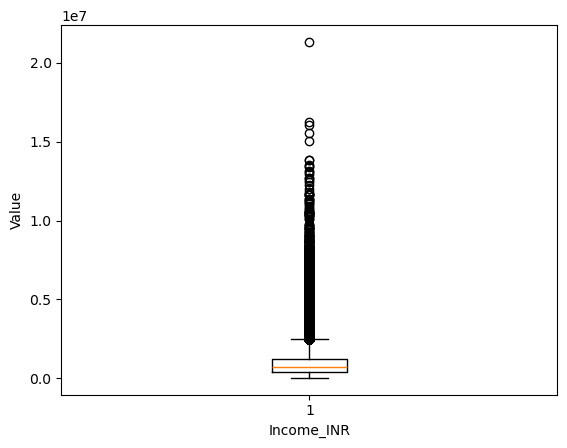

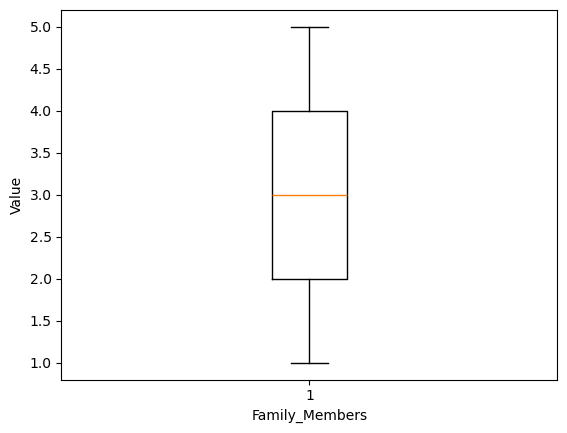

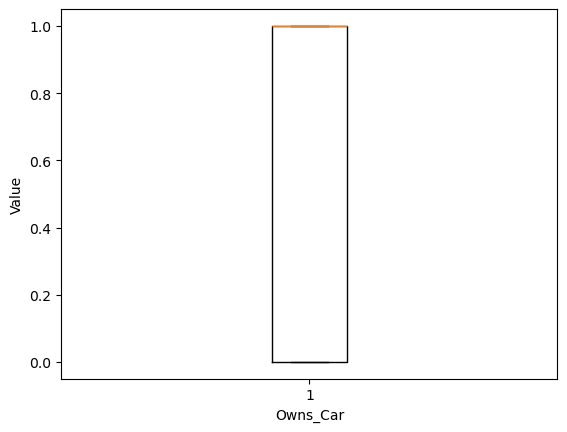

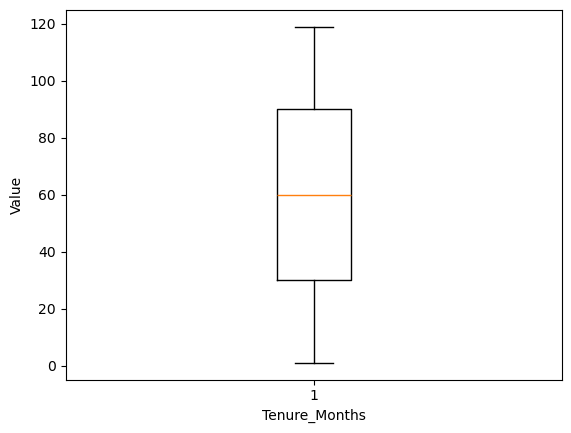

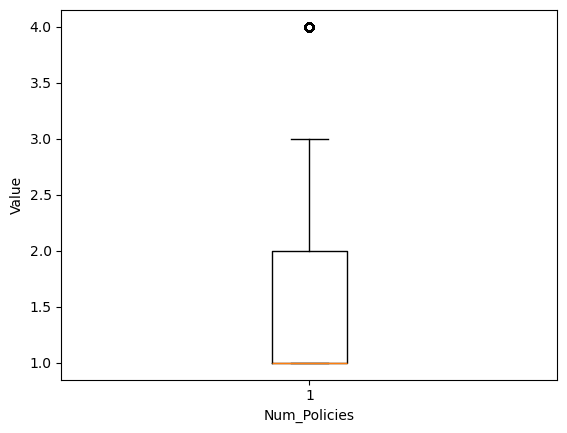

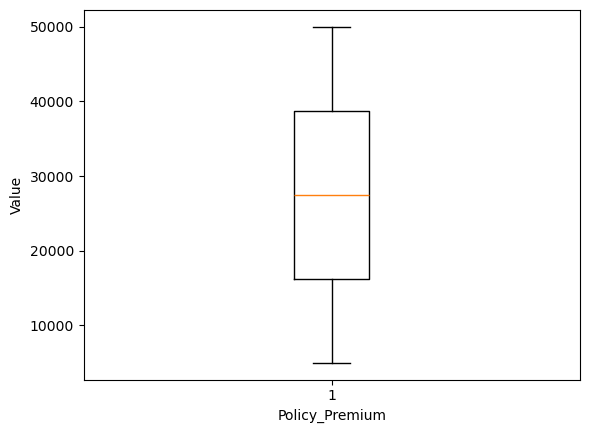

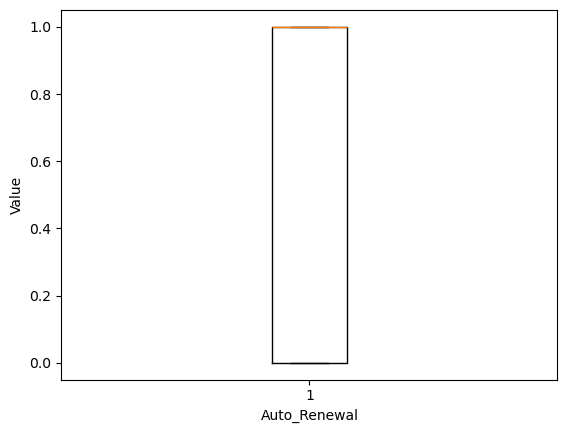

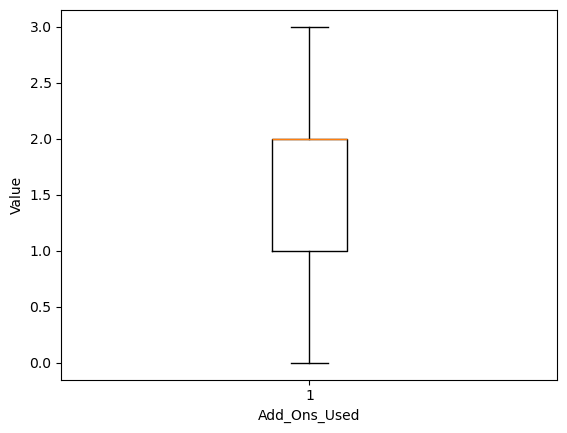

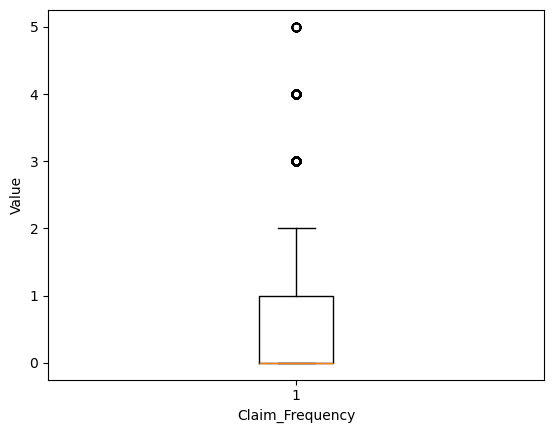

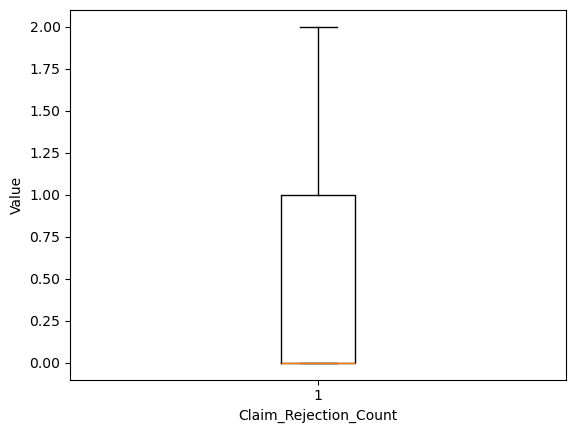

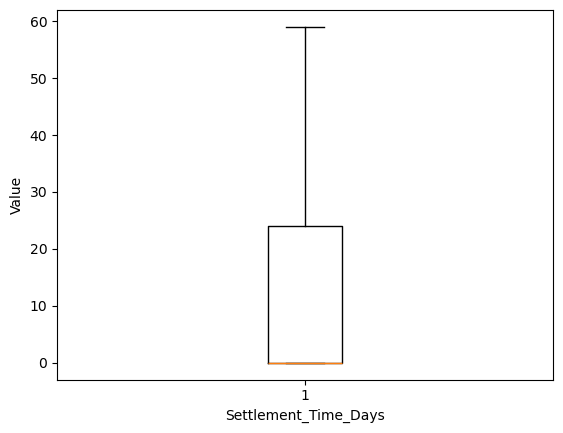

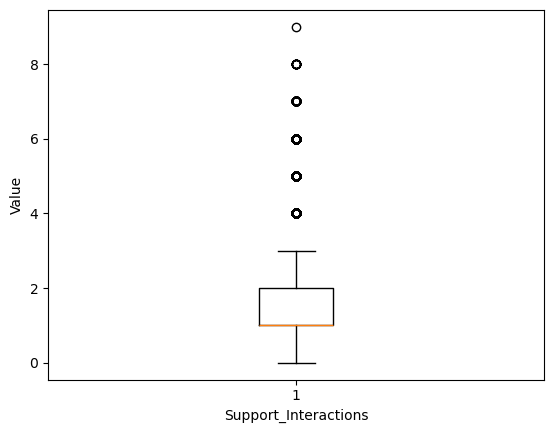

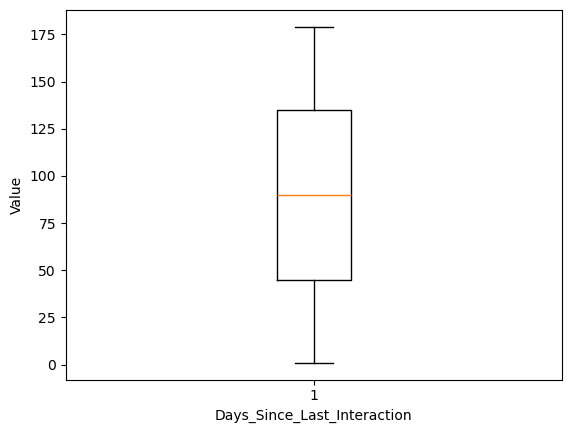

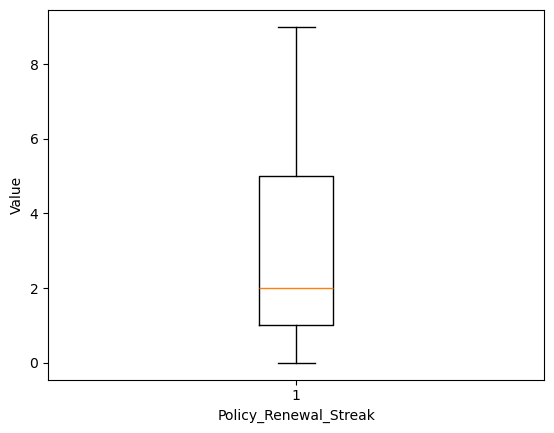

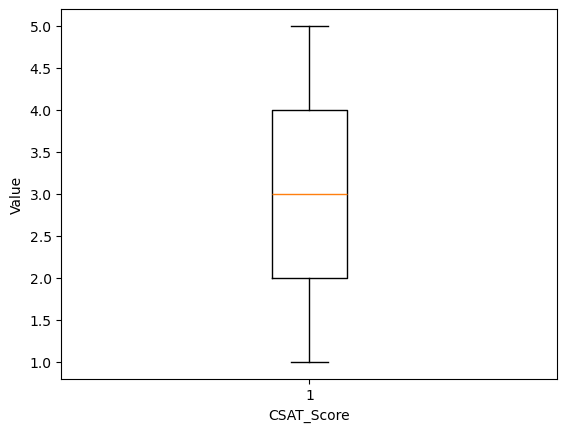

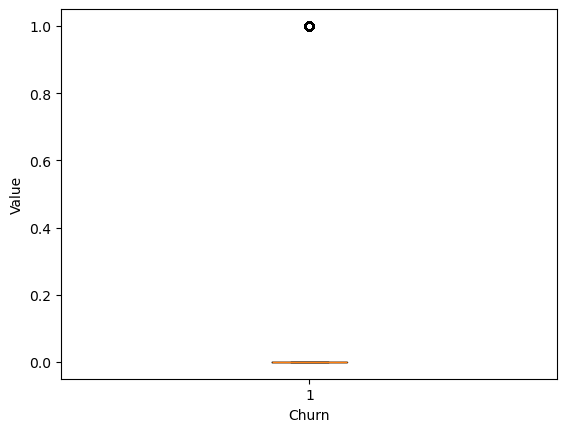

In [12]:
for col in df.select_dtypes(include="number").columns:
    values = df[col].dropna()
    if not values.empty:
        plt.figure()
        plt.boxplot(values)
        plt.xlabel(col)
        plt.ylabel("Value")
        plt.show()

In [13]:
Ins = ['Income_INR', 'Claim_Frequency', 'Support_Interactions']
for col in Ins:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    LW = Q1 - 1.5 * IQR
    UW = Q3 + 1.5 * IQR
    df = df[(df[col] >= LW) & (df[col] <= UW)]

### Data Preprocessing

In [14]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 84729 entries, 0 to 99997
Data columns (total 23 columns):
 #   Column                       Non-Null Count  Dtype   
---  ------                       --------------  -----   
 0   Gender                       84729 non-null  object  
 1   Location                     84729 non-null  object  
 2   Income_INR                   84729 non-null  float64 
 3   Family_Members               84729 non-null  int64   
 4   Owns_Car                     84729 non-null  int64   
 5   Occupation                   84729 non-null  object  
 6   Tenure_Months                84729 non-null  int64   
 7   Num_Policies                 84729 non-null  int64   
 8   Policy_Premium               84729 non-null  int64   
 9   Coverage_Type                84729 non-null  object  
 10  Payment_Method               84729 non-null  object  
 11  Auto_Renewal                 84729 non-null  int64   
 12  Add_Ons_Used                 84729 non-null  int64   
 13  Claim_

In [15]:
df.shape

(84729, 23)

In [16]:
from sklearn.preprocessing import LabelEncoder, StandardScaler

In [17]:
for col in df.columns:
    non_null = df[col].dropna()

    if not non_null.empty and non_null.map(
        lambda value: isinstance(value, pd.Interval)
    ).all():
        df[col] = df[col].map(
            lambda value: value.mid if isinstance(value, pd.Interval) else np.nan
        )

In [18]:
for i in df.columns:
    if df[i].dtype != 'object' and i != 'Churn':
        St = StandardScaler()
        df[i] = St.fit_transform(df[i].values.reshape(-1, 1))

    else:
        le = LabelEncoder()
        df[i] = le.fit_transform(df[i])

In [19]:
df.head()

,Gender,Location,Income_INR,Family_Members,Owns_Car,Occupation,Tenure_Months,Num_Policies,Policy_Premium,Coverage_Type,...,Claim_Frequency,Claim_Rejection_Count,Settlement_Time_Days,Support_Interactions,Days_Since_Last_Interaction,Policy_Renewal_Streak,CSAT_Score,Churn,Age_Group,Premium_Hike_Trend_Group
0,0,1,-0.460727,-0.712747,0.812695,2,0.495806,-0.699888,-0.766252,2,...,-0.730329,-0.550817,-0.670342,1.746402,0.872088,-0.371759,1.409935,0,0.540536,0.007545
1,0,1,0.684398,-0.004763,0.812695,1,0.524846,-0.699888,0.655048,1,...,0.841547,2.288607,2.424955,1.746402,1.143007,-1.222262,-0.002066,1,1.155211,0.714735
4,0,0,-0.468187,-0.712747,0.812695,1,-0.404450,1.626502,0.016903,1,...,-0.730329,-0.550817,-0.670342,0.722750,-0.250293,-1.222262,0.703934,0,0.540536,-0.699644
5,1,2,-0.152998,-0.712747,-1.230473,2,-1.653192,2.789697,-1.251175,0,...,-0.730329,-0.550817,-0.670342,0.722750,0.427006,-1.222262,-1.414068,0,-1.364957,0.007545
6,1,0,-1.139597,0.703222,0.812695,1,1.367021,-0.699888,0.659808,0,...,-0.730329,-0.550817,-0.670342,-1.324553,-0.985646,1.754498,-1.414068,0,-0.688814,-0.699644


### Splitting the Data

In [20]:
from sklearn.model_selection import train_test_split

In [21]:
X = df.drop(columns=['Churn'])
y = df['Churn']

In [22]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [23]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC

In [24]:
from sklearn.metrics import *

In [25]:
def train_and_evaluate_model(models, X_train, y_train, X_test, y_test):
    for model in models:
        model.fit(X_train, y_train)
        pred = model.predict(X_test)
        accuracy = accuracy_score(pred, y_test)
        print(f"{model} has Accuracy: {accuracy:.4f}")


In [26]:
models = [LogisticRegression(), DecisionTreeClassifier(), RandomForestClassifier(), KNeighborsClassifier(), SVC()]
train_and_evaluate_model(models, X_train, y_train, X_test, y_test)

LogisticRegression() has Accuracy: 0.9820
DecisionTreeClassifier() has Accuracy: 0.9720
RandomForestClassifier() has Accuracy: 0.9779
KNeighborsClassifier() has Accuracy: 0.9521
SVC() has Accuracy: 0.9829


In [27]:
lr = LogisticRegression()
lr.fit(X_train, y_train)
pred = lr.predict(X_test)

### Comparison Of Train & Test Data

In [31]:
compare = pd.DataFrame({'Actual': y_test, 'Predicted': pred})
compare['Changes'] = compare['Actual'] == compare['Predicted']
compare['Changes'].value_counts()

Changes
True     16641
False      305
Name: count, dtype: int64

In [32]:
compare.shape

(16946, 3)

In [41]:
print(f'{(305/16946)*100:.2f}%')

1.80%


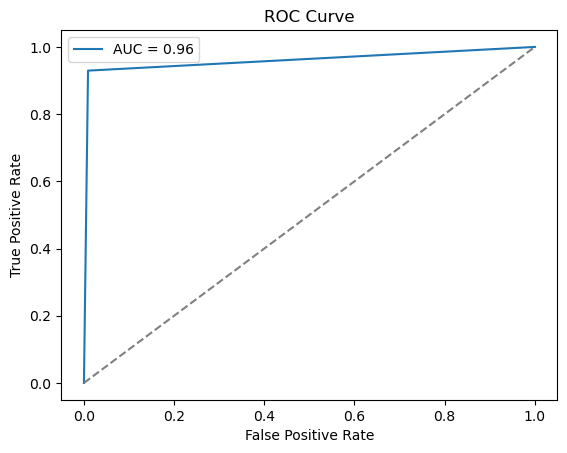

In [46]:

from sklearn.metrics import roc_curve, auc

fpr, tpr, _ = roc_curve(y_test, pred)
plt.plot(fpr, tpr, label=f"AUC = {auc(fpr, tpr):.2f}")
plt.plot([0,1],[0,1],'--',color='gray')
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()
plt.show()
